
### Project Requirements

#### 1. Dataset and Preprocessing


* Load the Sentiment140 dataset. link https://www.kaggle.com/datasets/ferno2/training1600000processednoemoticoncsv/data
* Select the sentiment and tweet text columns.
* Keep positive and negative tweets only.
* Convert sentiment labels to:

  * Negative = 0
  * Positive = 1
* Apply the required text preprocessing.
* Split the dataset into training and testing sets.
* Apply TF-IDF vectorization.

#### 2. Traditional Machine Learning Models

Students must implement the following models using TF-IDF features:

* Bernoulli Naive Bayes
* Linear Support Vector Machine (SVM)
* Logistic Regression

For each model, students must:

* Train the model.
* Make predictions on the test set.
* Calculate accuracy.
* Display the classification report.

#### 3. CBOW Word Embeddings

Students must implement CBOW (Continuous Bag of Words) to learn word embeddings from the training tweets.

Requirements:

* Train CBOW from scratch.
* Do not use pretrained word embeddings.
* Extract the embedding vector for one selected word.
* Display the selected word and its embedding vector.
* Use the generated CBOW embeddings as input representations for a Deep Learning sentiment classification model.

#### 4. Skip-gram Word Embeddings

Students must implement Skip-gram to learn word embeddings from the training tweets.

Requirements:

* Train Skip-gram from scratch.
* Do not use pretrained word embeddings.
* Extract the embedding vector for the same word selected in the CBOW task.
* Display the selected word and its embedding vector.
* Use the generated Skip-gram embeddings as input representations for a Deep Learning sentiment classification model.

#### 5. Deep Learning Classification

Students must implement two Deep Learning models:

**Model 1: CBOW + Deep Learning**

* Use the word embeddings learned using CBOW.
* Build a simple neural network for sentiment classification.
* Train the model.
* Predict sentiment on the test set.

**Model 2: Skip-gram + Deep Learning**

* Use the word embeddings learned using Skip-gram.
* Build a simple neural network for sentiment classification.
* Train the model.
* Predict sentiment on the test set.

The Deep Learning architecture should include:

* Embedding layer, if required
* Flatten or GlobalAveragePooling1D
* Dense hidden layer
* Dropout, if needed
* Output layer with sigmoid activation

Keep the implementation simple and suitable for students learning Deep Learning.

#### 6. Model Evaluation

Students must evaluate all models using:

* Accuracy
* Precision
* Recall
* F1-score
* Classification Report

Students must compare the performance of:

1. Bernoulli Naive Bayes
2. Linear SVM
3. Logistic Regression
4. CBOW + Deep Learning
5. Skip-gram + Deep Learning

They must present the comparison in a table and identify the best-performing model.

#### 7. Sample Predictions

Students must test the trained models on the following tweets:

* "I love this!"
* "I hate that!"
* "It was okay, not great."

They must display the predicted sentiment for each tweet.

### Student Submission Requirements

Students must submit:

1. Their completed Python code or Jupyter Notebook.
2. Accuracy and classification reports for all models.
3. The extracted CBOW and Skip-gram word embedding vectors.
4. A comparison table of all five models.
5. A short discussion explaining:

   * The difference between CBOW and Skip-gram.
   * Which embedding method performed better.
   * Which model achieved the best classification results.
   * Why different models may produce different results.



# Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

RANDOM_STATE = 42

In [3]:
DATASET_PATH = "training.1600000.processed.noemoticon.csv"

df = pd.read_csv(
    DATASET_PATH,
    encoding="latin-1",
    header=None
)

print("Dataset Loaded Successfully!")
print("Shape:", df.shape)

Dataset Loaded Successfully!
Shape: (1600000, 6)


In [4]:
df.columns = [
    "sentiment",
    "id",
    "date",
    "query",
    "user",
    "text"
]

df.head()

,sentiment,id,date,query,user,text
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all...."


In [5]:
df = df[["sentiment", "text"]].copy()

df.head()

,sentiment,text
0,0,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,is upset that he can't update his Facebook by ...
2,0,@Kenichan I dived many times for the ball. Man...
3,0,my whole body feels itchy and like its on fire
4,0,"@nationwideclass no, it's not behaving at all...."


# Data Exploration (EDA)

In [6]:
print("Dataset Information:")
print(df.info())

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600000 entries, 0 to 1599999
Data columns (total 2 columns):
 #   Column     Non-Null Count    Dtype 
---  ------     --------------    ----- 
 0   sentiment  1600000 non-null  int64 
 1   text       1600000 non-null  object
dtypes: int64(1), object(1)
memory usage: 24.4+ MB
None

Dataset Shape:
(1600000, 2)

Missing Values:
sentiment    0
text         0
dtype: int64

Duplicate Rows:
16309


In [7]:
print(df["sentiment"].value_counts())

sentiment
0    800000
4    800000
Name: count, dtype: int64


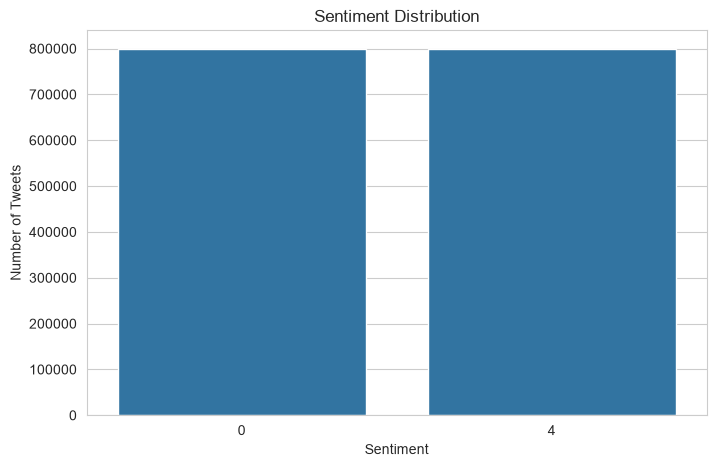

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment"
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")

plt.show()

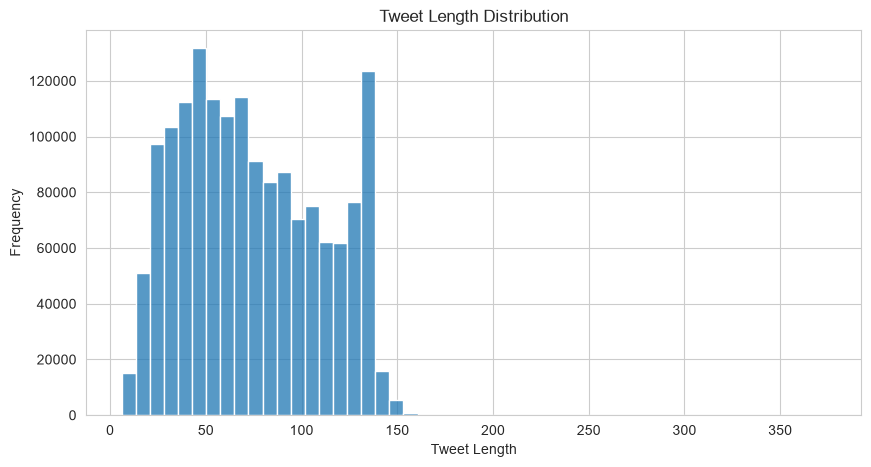

In [9]:
df["text_length"] = df["text"].apply(len)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="text_length",
    bins=50
)

plt.title("Tweet Length Distribution")
plt.xlabel("Tweet Length")
plt.ylabel("Frequency")

plt.show()

In [10]:
df.dropna(inplace=True)

df.drop_duplicates(subset=["text"], inplace=True)

df.reset_index(drop=True, inplace=True)

print("Shape after cleaning:", df.shape)

Shape after cleaning: (1581466, 3)


In [11]:
df["sentiment"] = df["sentiment"].map({
    0: 0,
    4: 1
})

df.dropna(subset=["sentiment"], inplace=True)

df["sentiment"] = df["sentiment"].astype(int)

print(df["sentiment"].value_counts())

sentiment
1    791281
0    790185
Name: count, dtype: int64


# Text Preprocessing

In [12]:
def preprocess_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove user mentions
    text = re.sub(r"@\w+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [13]:
df["clean_text"] = df["text"].apply(preprocess_text)

df[["text", "clean_text"]].head(10)

,text,clean_text
0,"@switchfoot http://twitpic.com/2y1zl - Awww, t...",a that s a bummer you shoulda got david carr o...
1,is upset that he can't update his Facebook by ...,is upset that he can t update his facebook by ...
2,@Kenichan I dived many times for the ball. Man...,i dived many times for the ball managed to sav...
3,my whole body feels itchy and like its on fire,my whole body feels itchy and like its on fire
4,"@nationwideclass no, it's not behaving at all....",no it s not behaving at all i m mad why am i h...
5,@Kwesidei not the whole crew,not the whole crew
6,Need a hug,need a hug
7,@LOLTrish hey long time no see! Yes.. Rains a...,hey long time no see yes rains a bit only a bi...
8,@Tatiana_K nope they didn't have it,nope they didn t have it
9,@twittera que me muera ?,que me muera


In [14]:
df = df[df["clean_text"].str.len() > 0].copy()

df.reset_index(drop=True, inplace=True)

print("Final Dataset Shape:", df.shape)

Final Dataset Shape: (1577939, 4)


In [15]:
X = df["clean_text"]
y = df["sentiment"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (1577939,)
y Shape: (1577939,)


# Train Test Split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 1262351
Testing Samples: 315588


# TF-IDF Vectorization

In [17]:
tfidf = TfidfVectorizer(
    max_features=100000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

In [18]:
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("Vocabulary Size:", len(tfidf.vocabulary_))

Training TF-IDF Shape: (1262351, 100000)
Testing TF-IDF Shape: (315588, 100000)
Vocabulary Size: 100000


# Traditional Machine Learning

In [20]:

results = []

def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(y_true, y_pred, average="weighted")

    recall = recall_score(y_true, y_pred, average="weighted")

    f1 = f1_score(y_true, y_pred, average="weighted")

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print(f"\n{model_name} Evaluation")
    print("=" * 50)

    print("Accuracy:", accuracy)

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["Negative", "Positive"]
    ))

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"]
    )

    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

# Bernoulli Naive Bayes


Bernoulli Naive Bayes Evaluation
Accuracy: 0.7919882885280809

Classification Report:
              precision    recall  f1-score   support

    Negative       0.80      0.78      0.79    157715
    Positive       0.78      0.81      0.80    157873

    accuracy                           0.79    315588
   macro avg       0.79      0.79      0.79    315588
weighted avg       0.79      0.79      0.79    315588



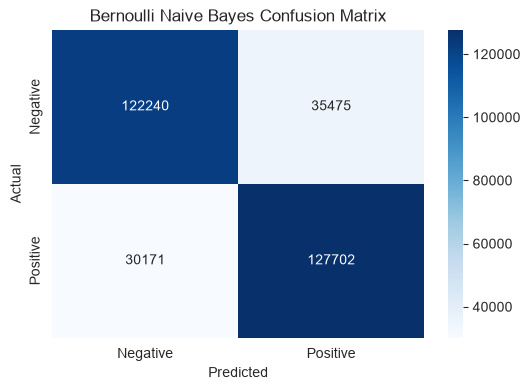

In [21]:
from sklearn.naive_bayes import BernoulliNB

bnb_model = BernoulliNB(
    alpha=1.0,
    binarize=0.0
)

bnb_model.fit(X_train_tfidf, y_train)

bnb_predictions = bnb_model.predict(X_test_tfidf)

evaluate_model(
    "Bernoulli Naive Bayes",
    y_test,
    bnb_predictions
)

# Linear Support Vector Machine (SVM)


Linear SVM Evaluation
Accuracy: 0.8153351838472945

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.80      0.81    157715
    Positive       0.81      0.83      0.82    157873

    accuracy                           0.82    315588
   macro avg       0.82      0.82      0.82    315588
weighted avg       0.82      0.82      0.82    315588



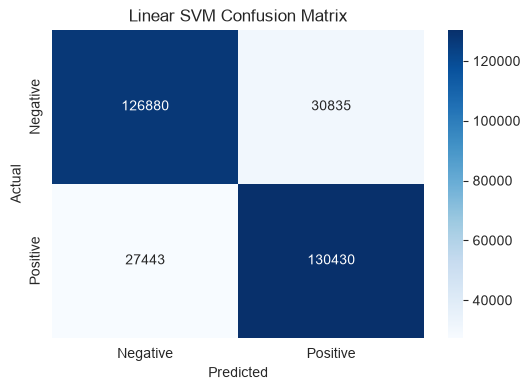

In [22]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    C=1.0,
    random_state=RANDOM_STATE,
    max_iter=2000
)

svm_model.fit(X_train_tfidf, y_train)

svm_predictions = svm_model.predict(X_test_tfidf)

evaluate_model(
    "Linear SVM",
    y_test,
    svm_predictions
)

# Logistic Regression


Logistic Regression Evaluation
Accuracy: 0.8204019164226777

Classification Report:
              precision    recall  f1-score   support

    Negative       0.83      0.81      0.82    157715
    Positive       0.81      0.83      0.82    157873

    accuracy                           0.82    315588
   macro avg       0.82      0.82      0.82    315588
weighted avg       0.82      0.82      0.82    315588



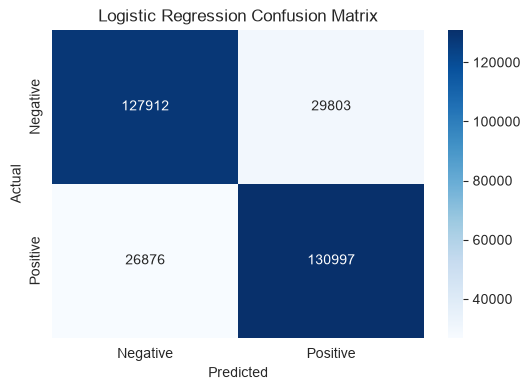

In [23]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    random_state=RANDOM_STATE,
    solver="liblinear"
)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions
)

In [24]:
ml_results = pd.DataFrame(results)

ml_results.sort_values(
    by="F1-Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1-Score
2,Logistic Regression,0.820402,0.820511,0.820402,0.820386
1,Linear SVM,0.815335,0.815479,0.815335,0.815313
0,Bernoulli Naive Bayes,0.791988,0.792315,0.791988,0.791928


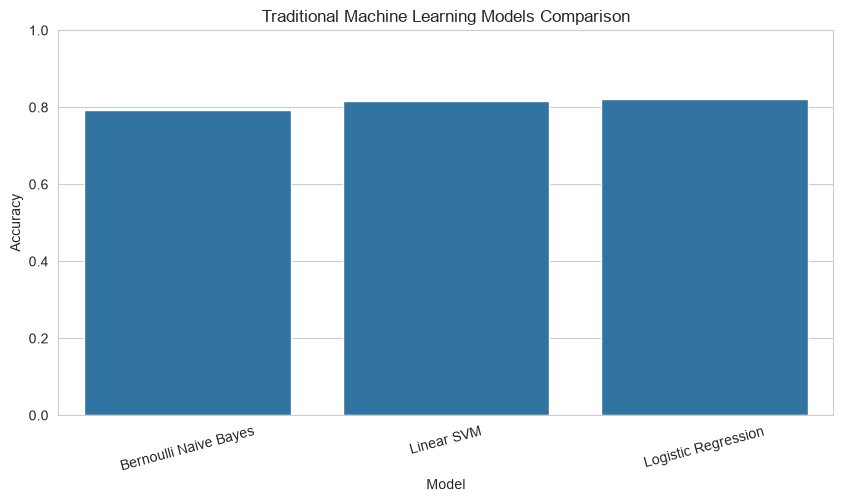

In [25]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=ml_results,
    x="Model",
    y="Accuracy"
)

plt.title("Traditional Machine Learning Models Comparison")
plt.xticks(rotation=15)
plt.ylim(0, 1)

plt.show()

# CBOW Word Embeddings

In [26]:
from collections import Counter

# Tokenize training tweets
train_tokens = [
    text.split()
    for text in X_train
]

# Count word frequencies
word_counts = Counter(
    word
    for tweet in train_tokens
    for word in tweet
)

# Build vocabulary
vocab = {
    word: idx + 1
    for idx, (word, count) in enumerate(
        word_counts.most_common(30000)
    )
}

vocab["<PAD>"] = 0

# Reverse vocabulary
id_to_word = {
    idx: word
    for word, idx in vocab.items()
}

vocab_size = len(vocab)

print("Vocabulary Size:", vocab_size)

Vocabulary Size: 30001


In [27]:
def encode_tweets(texts, vocab, max_length=40):

    encoded = []

    for text in texts:

        tokens = text.split()

        token_ids = [
            vocab[word]
            for word in tokens
            if word in vocab
        ]

        token_ids = token_ids[:max_length]

        token_ids += [0] * (max_length - len(token_ids))

        encoded.append(token_ids)

    return np.array(encoded, dtype=np.int32)


MAX_LENGTH = 40

X_train_seq = encode_tweets(
    X_train,
    vocab,
    MAX_LENGTH
)

X_test_seq = encode_tweets(
    X_test,
    vocab,
    MAX_LENGTH
)

print("Training Sequence Shape:", X_train_seq.shape)
print("Testing Sequence Shape:", X_test_seq.shape)

Training Sequence Shape: (1262351, 40)
Testing Sequence Shape: (315588, 40)


In [28]:
def generate_cbow_pairs(sequences, window_size=2):

    contexts = []
    targets = []

    for sequence in sequences:

        words = [
            word for word in sequence
            if word != 0
        ]

        for i in range(window_size, len(words) - window_size):

            context = (
                words[i-window_size:i] +
                words[i+1:i+window_size+1]
            )

            target = words[i]

            contexts.append(context)
            targets.append(target)

    return (
        np.array(contexts, dtype=np.int32),
        np.array(targets, dtype=np.int32)
    )


X_cbow, y_cbow = generate_cbow_pairs(
    X_train_seq,
    window_size=2
)

print("CBOW Context Shape:", X_cbow.shape)
print("CBOW Target Shape:", y_cbow.shape)

CBOW Context Shape: (11231515, 4)
CBOW Target Shape: (11231515,)


In [29]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    GlobalAveragePooling1D,
    Dense
)

EMBEDDING_DIM = 100

cbow_model = Sequential([
    Input(shape=(4,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        name="cbow_embedding"
    ),

    GlobalAveragePooling1D(),

    Dense(
        vocab_size,
        activation="softmax"
    )
])

cbow_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cbow_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ cbow_embedding (Embedding)           │ (None, 4, 100)              │       3,000,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 100)                 │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 30001)               │       3,030,101 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,030,201 (23.00 MB)

 Trainable params: 6,030,201 (23.00 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
def cbow_generator(sequences, vocab_size, window_size=2):

    while True:

        for sequence in sequences:

            words = [
                word for word in sequence
                if word != 0
            ]

            for i in range(window_size, len(words) - window_size):

                context = (
                    words[i-window_size:i] +
                    words[i+1:i+window_size+1]
                )

                target = words[i]

                yield (
                    np.array(context, dtype=np.int32),
                    np.int32(target)
                )

In [31]:
BATCH_SIZE = 512

steps_per_epoch = 1000

cbow_dataset = tf.data.Dataset.from_generator(
    lambda: cbow_generator(
        X_train_seq,
        vocab_size,
        window_size=2
    ),
    output_signature=(
        tf.TensorSpec(shape=(4,), dtype=tf.int32),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

cbow_history = cbow_model.fit(
    cbow_dataset,
    epochs=5,
    steps_per_epoch=steps_per_epoch
)

Epoch 1/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 247s 246ms/step - accuracy: 0.0630 - loss: 7.0200 
Epoch 2/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 244s 244ms/step - accuracy: 0.1060 - loss: 6.2703
Epoch 3/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 227s 227ms/step - accuracy: 0.1263 - loss: 6.0541
Epoch 4/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 237s 237ms/step - accuracy: 0.1408 - loss: 5.9008
Epoch 5/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 262s 262ms/step - accuracy: 0.1518 - loss: 5.7885


In [32]:
selected_word = "love"

if selected_word in vocab:

    word_id = vocab[selected_word]

    cbow_embedding_layer = cbow_model.get_layer(
        "cbow_embedding"
    )

    cbow_vector = cbow_embedding_layer.get_weights()[0][word_id]

    print("Selected Word:", selected_word)
    print("CBOW Embedding Vector:")
    print(cbow_vector)

    print("Vector Shape:", cbow_vector.shape)

else:
    print("Word not found in vocabulary.")

Selected Word: love
CBOW Embedding Vector:
[-0.14999513  0.27508032 -0.04599521 -0.56416214  0.17300422  0.06526039
  0.02697152 -0.3041861   0.05099368  0.12292847 -0.21798348  0.36345774
  0.22020178  0.24910855 -1.0063988   0.04451302 -0.17945626 -0.754962
  0.20963019  0.2427319   0.02484202 -0.26175642  0.41602895  0.18146658
 -0.01549647 -0.11209145  0.67168784  0.30238983 -0.4572611  -0.23505236
  0.17592333 -0.79508674  0.0069815   0.21858452  0.3672919   0.27061528
  0.10627069 -0.669142    0.8753024  -0.1476655  -0.54102075  0.42341447
 -0.07504061  0.40058506 -0.19824493 -0.08733634  0.91580045  0.9407803
  0.7307628  -0.34363583  0.3921998   0.11553127  0.3083652  -0.66230136
  0.10865389 -0.03736179  1.1285024   0.09536661  0.5343689  -0.12646165
 -0.5193709  -0.2836385  -0.43542203  0.11362509 -0.17274351  0.13753743
 -1.1078409  -0.06112052  0.9915452  -0.44457585 -0.6413912  -0.45966157
  0.28030595 -0.51189405 -0.88304156  0.151457    0.14108755  0.7067796
  0.2037637 

In [33]:
def skipgram_generator(sequences, window_size=2):

    while True:

        for sequence in sequences:

            words = [
                word for word in sequence
                if word != 0
            ]

            for i, target in enumerate(words):

                start = max(0, i - window_size)
                end = min(len(words), i + window_size + 1)

                for j in range(start, end):

                    if i != j:

                        context = words[j]

                        yield (
                            np.array([target], dtype=np.int32),
                            np.int32(context)
                        )

In [34]:
skipgram_model = Sequential([
    Input(shape=(1,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        name="skipgram_embedding"
    ),

    tf.keras.layers.Flatten(),

    Dense(
        vocab_size,
        activation="softmax"
    )
])

skipgram_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

skipgram_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ skipgram_embedding (Embedding)       │ (None, 1, 100)              │       3,000,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 30001)               │       3,030,101 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,030,201 (23.00 MB)

 Trainable params: 6,030,201 (23.00 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
skipgram_dataset = tf.data.Dataset.from_generator(
    lambda: skipgram_generator(
        X_train_seq,
        window_size=2
    ),
    output_signature=(
        tf.TensorSpec(shape=(1,), dtype=tf.int32),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [36]:
skipgram_history = skipgram_model.fit(
    skipgram_dataset,
    epochs=5,
    steps_per_epoch=steps_per_epoch
)

Epoch 1/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 235s 234ms/step - accuracy: 0.0473 - loss: 7.6035 
Epoch 2/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 265s 265ms/step - accuracy: 0.0592 - loss: 6.8449
Epoch 3/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 243s 243ms/step - accuracy: 0.0632 - loss: 6.7480
Epoch 4/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 240s 240ms/step - accuracy: 0.0649 - loss: 6.6828
Epoch 5/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 244s 244ms/step - accuracy: 0.0684 - loss: 6.6125


In [37]:
if selected_word in vocab:

    word_id = vocab[selected_word]

    skipgram_embedding_layer = skipgram_model.get_layer(
        "skipgram_embedding"
    )

    skipgram_vector = skipgram_embedding_layer.get_weights()[0][word_id]

    print("Selected Word:", selected_word)
    print("Skip-gram Embedding Vector:")
    print(skipgram_vector)

    print("Vector Shape:", skipgram_vector.shape)

Selected Word: love
Skip-gram Embedding Vector:
[-0.1608228  -0.04522679 -0.23260526 -0.04029964  0.02504809 -0.14281113
 -0.28524542  0.38879928  0.03558592 -0.06552224  0.24010034  0.04010239
 -0.43558243 -0.05107014 -0.12049343 -0.18257277 -0.17332254 -0.00323151
  0.17111322  0.02813333 -0.13296638 -0.15350696  0.19573978  0.20060454
  0.5765227  -0.31020495  0.11986177  0.09318648 -0.02103661  0.02378848
 -0.01155553  0.13352074 -0.09890624  0.03291133 -0.11635331 -0.20418943
 -0.06652622 -0.4594155  -0.22265501  0.07788946  0.30685565 -0.23138255
  0.13540989 -0.10714063  0.03253175  0.08650515 -0.09764861 -0.10998449
 -0.02998658 -0.21775582 -0.22189702  0.24414116  0.12013594  0.09719825
 -0.11161955 -0.12336116 -0.00123417 -0.27392203 -0.02757004  0.06085413
 -0.14041555 -0.03937546 -0.0160036  -0.06510941  0.1950184  -0.02476302
  0.01090685  0.13739896 -0.28205657  0.04567634 -0.05500766 -0.06690892
 -0.13624404 -0.10079394  0.07300147  0.1236164   0.0007972   0.06172867
 -0

In [38]:
print("CBOW Vector:")
print(cbow_vector)

print("\nSkip-gram Vector:")
print(skipgram_vector)

print("\nCBOW Shape:", cbow_vector.shape)
print("Skip-gram Shape:", skipgram_vector.shape)

CBOW Vector:
[-0.14999513  0.27508032 -0.04599521 -0.56416214  0.17300422  0.06526039
  0.02697152 -0.3041861   0.05099368  0.12292847 -0.21798348  0.36345774
  0.22020178  0.24910855 -1.0063988   0.04451302 -0.17945626 -0.754962
  0.20963019  0.2427319   0.02484202 -0.26175642  0.41602895  0.18146658
 -0.01549647 -0.11209145  0.67168784  0.30238983 -0.4572611  -0.23505236
  0.17592333 -0.79508674  0.0069815   0.21858452  0.3672919   0.27061528
  0.10627069 -0.669142    0.8753024  -0.1476655  -0.54102075  0.42341447
 -0.07504061  0.40058506 -0.19824493 -0.08733634  0.91580045  0.9407803
  0.7307628  -0.34363583  0.3921998   0.11553127  0.3083652  -0.66230136
  0.10865389 -0.03736179  1.1285024   0.09536661  0.5343689  -0.12646165
 -0.5193709  -0.2836385  -0.43542203  0.11362509 -0.17274351  0.13753743
 -1.1078409  -0.06112052  0.9915452  -0.44457585 -0.6413912  -0.45966157
  0.28030595 -0.51189405 -0.88304156  0.151457    0.14108755  0.7067796
  0.2037637   0.33263725 -0.46151888  0.20

# Deep Learning Classification

In [39]:
y_train_dl = np.asarray(y_train, dtype=np.float32)
y_test_dl = np.asarray(y_test, dtype=np.float32)

print("Training Labels:", y_train_dl.shape)
print("Testing Labels:", y_test_dl.shape)

Training Labels: (1262351,)
Testing Labels: (315588,)


In [40]:
from tensorflow.keras.layers import (
    Input,
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)

from tensorflow.keras.models import Sequential

cbow_weights = cbow_model.get_layer(
    "cbow_embedding"
).get_weights()[0]

cbow_classifier = Sequential([

    Input(shape=(MAX_LENGTH,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        weights=[cbow_weights],
        trainable=True,
        mask_zero=True
    ),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

cbow_classifier.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cbow_classifier.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 40, 100)             │       3,000,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d_1           │ (None, 100)                 │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           6,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,006,629 (11.47 MB)

 Trainable params: 3,006,629 (11.47 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
cbow_dl_history = cbow_classifier.fit(
    X_train_seq,
    y_train_dl,
    validation_split=0.1,
    epochs=5,
    batch_size=512,
    verbose=1
)

Epoch 1/5
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 68s 30ms/step - accuracy: 0.4997 - loss: 0.6932 - val_accuracy: 0.5005 - val_loss: 0.6931
Epoch 2/5
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 67s 30ms/step - accuracy: 0.4994 - loss: 0.6932 - val_accuracy: 0.4995 - val_loss: 0.6931
Epoch 3/5
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 82s 30ms/step - accuracy: 0.5003 - loss: 0.6932 - val_accuracy: 0.4995 - val_loss: 0.6931
Epoch 4/5
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 68s 31ms/step - accuracy: 0.4995 - loss: 0.6932 - val_accuracy: 0.4995 - val_loss: 0.6932
Epoch 5/5
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 65s 29ms/step - accuracy: 0.5012 - loss: 0.6931 - val_accuracy: 0.4995 - val_loss: 0.6932


617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step

CBOW + Deep Learning Evaluation
Accuracy: 0.5002503263748939

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00    157715
    Positive       0.50      1.00      0.67    157873

    accuracy                           0.50    315588
   macro avg       0.25      0.50      0.33    315588
weighted avg       0.25      0.50      0.33    315588



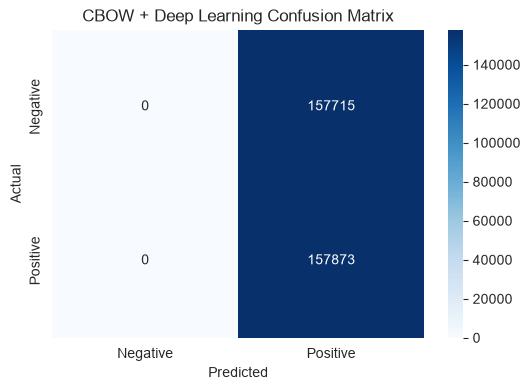

In [42]:
cbow_dl_probabilities = cbow_classifier.predict(
    X_test_seq,
    batch_size=512
)

cbow_dl_predictions = (
    cbow_dl_probabilities >= 0.5
).astype(int).flatten()

evaluate_model(
    "CBOW + Deep Learning",
    y_test,
    cbow_dl_predictions
)

In [43]:
skipgram_weights = skipgram_model.get_layer(
    "skipgram_embedding"
).get_weights()[0]

skipgram_classifier = Sequential([

    Input(shape=(MAX_LENGTH,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        weights=[skipgram_weights],
        trainable=True,
        mask_zero=True
    ),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

skipgram_classifier.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

skipgram_classifier.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ (None, 40, 100)             │       3,000,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d_2           │ (None, 100)                 │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           6,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,006,629 (11.47 MB)

 Trainable params: 3,006,629 (11.47 MB)

 Non-trainable params: 0 (0.00 B)

In [44]:
skipgram_dl_history = skipgram_classifier.fit(
    X_train_seq,
    y_train_dl,
    validation_split=0.1,
    epochs=5,
    batch_size=512,
    verbose=1
)

Epoch 1/5
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 71s 31ms/step - accuracy: 0.5010 - loss: 0.6931 - val_accuracy: 0.5005 - val_loss: 0.6931
Epoch 2/5
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 68s 31ms/step - accuracy: 0.5005 - loss: 0.6931 - val_accuracy: 0.5005 - val_loss: 0.6932
Epoch 3/5
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 86s 33ms/step - accuracy: 0.4996 - loss: 0.6932 - val_accuracy: 0.4995 - val_loss: 0.6932
Epoch 4/5
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 67s 30ms/step - accuracy: 0.4998 - loss: 0.6932 - val_accuracy: 0.4995 - val_loss: 0.6932
Epoch 5/5
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 63s 28ms/step - accuracy: 0.4998 - loss: 0.6932 - val_accuracy: 0.4995 - val_loss: 0.6931


617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step

Skip-gram + Deep Learning Evaluation
Accuracy: 0.5002503263748939

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00    157715
    Positive       0.50      1.00      0.67    157873

    accuracy                           0.50    315588
   macro avg       0.25      0.50      0.33    315588
weighted avg       0.25      0.50      0.33    315588



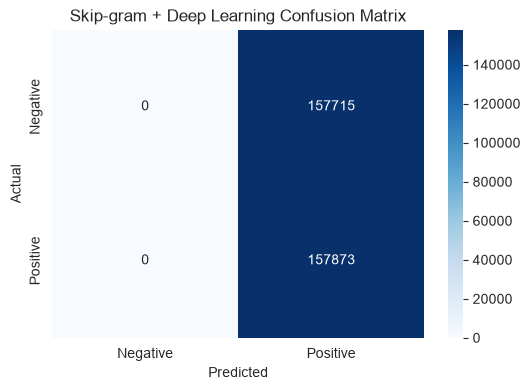

In [45]:
skipgram_dl_probabilities = skipgram_classifier.predict(
    X_test_seq,
    batch_size=512
)

skipgram_dl_predictions = (
    skipgram_dl_probabilities >= 0.5
).astype(int).flatten()

evaluate_model(
    "Skip-gram + Deep Learning",
    y_test,
    skipgram_dl_predictions
)

In [46]:
final_results = pd.DataFrame(results)

final_results = final_results.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

final_results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8204,0.8205,0.8204,0.8204
1,Linear SVM,0.8153,0.8155,0.8153,0.8153
2,Bernoulli Naive Bayes,0.7920,0.7923,0.7920,0.7919
3,CBOW + Deep Learning,0.5003,0.2503,0.5003,0.3336
4,Skip-gram + Deep Learning,0.5003,0.2503,0.5003,0.3336


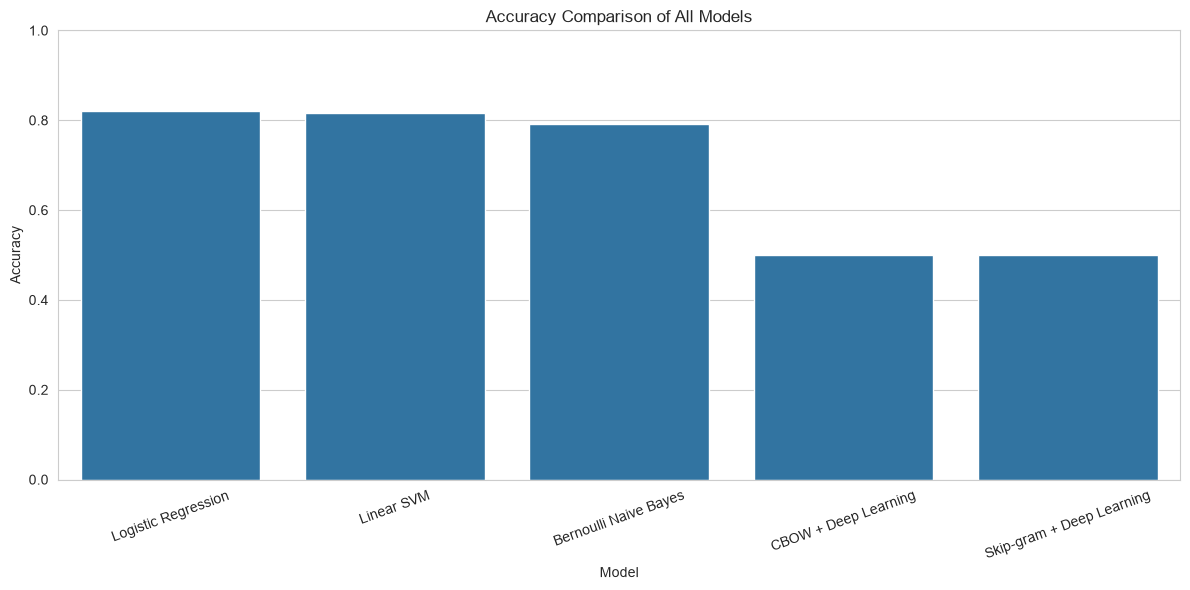

In [47]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=final_results,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of All Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

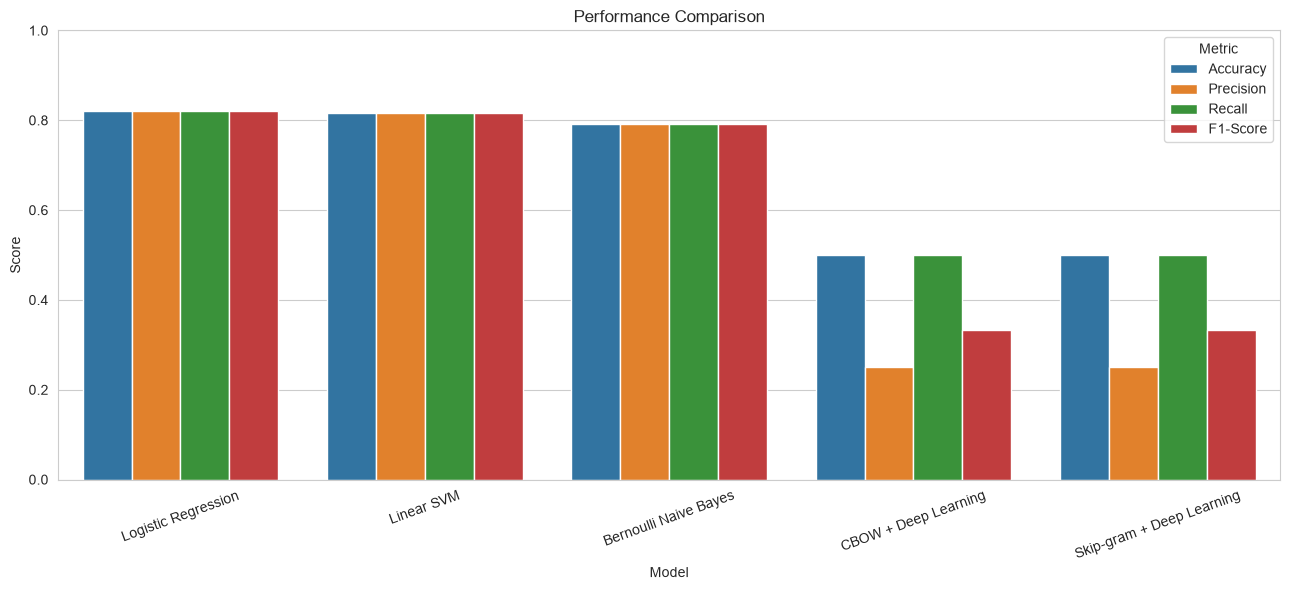

In [48]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

comparison = final_results.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=comparison,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [49]:
best_model = final_results.iloc[0]

print("Best Performing Model:")
print("Model:", best_model["Model"])
print("Accuracy:", best_model["Accuracy"])
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1-Score:", best_model["F1-Score"])

Best Performing Model:
Model: Logistic Regression
Accuracy: 0.8204019164226777
Precision: 0.8205105331104485
Recall: 0.8204019164226777
F1-Score: 0.8203856317089193


In [50]:
embedding_comparison = final_results[
    final_results["Model"].isin([
        "CBOW + Deep Learning",
        "Skip-gram + Deep Learning"
    ])
]

print(embedding_comparison)

                       Model  Accuracy  Precision   Recall  F1-Score
3       CBOW + Deep Learning   0.50025    0.25025  0.50025  0.333612
4  Skip-gram + Deep Learning   0.50025    0.25025  0.50025  0.333612


In [51]:
def predict_sentiment(text, model_name):

    cleaned_text = preprocess_text(text)

    if model_name == "Bernoulli Naive Bayes":

        features = tfidf.transform([cleaned_text])
        prediction = bnb_model.predict(features)[0]

    elif model_name == "Linear SVM":

        features = tfidf.transform([cleaned_text])
        prediction = svm_model.predict(features)[0]

    elif model_name == "Logistic Regression":

        features = tfidf.transform([cleaned_text])
        prediction = lr_model.predict(features)[0]

    elif model_name == "CBOW + Deep Learning":

        features = encode_tweets(
            [cleaned_text],
            vocab,
            MAX_LENGTH
        )

        probability = cbow_classifier.predict(
            features,
            verbose=0
        )[0][0]

        prediction = int(probability >= 0.5)

    elif model_name == "Skip-gram + Deep Learning":

        features = encode_tweets(
            [cleaned_text],
            vocab,
            MAX_LENGTH
        )

        probability = skipgram_classifier.predict(
            features,
            verbose=0
        )[0][0]

        prediction = int(probability >= 0.5)

    else:
        raise ValueError("Unknown model name")

    return "Positive" if prediction == 1 else "Negative"

In [52]:
sample_tweets = [
    "I love this!",
    "I hate that!",
    "It was okay, not great."
]

model_names = [
    "Bernoulli Naive Bayes",
    "Linear SVM",
    "Logistic Regression",
    "CBOW + Deep Learning",
    "Skip-gram + Deep Learning"
]

sample_results = []

for tweet in sample_tweets:

    for model_name in model_names:

        prediction = predict_sentiment(
            tweet,
            model_name
        )

        sample_results.append({
            "Tweet": tweet,
            "Model": model_name,
            "Predicted Sentiment": prediction
        })

sample_predictions_df = pd.DataFrame(sample_results)

sample_predictions_df

,Tweet,Model,Predicted Sentiment
0,I love this!,Bernoulli Naive Bayes,Positive
1,I love this!,Linear SVM,Positive
2,I love this!,Logistic Regression,Positive
3,I love this!,CBOW + Deep Learning,Positive
4,I love this!,Skip-gram + Deep Learning,Positive
5,I hate that!,Bernoulli Naive Bayes,Negative
6,I hate that!,Linear SVM,Negative
7,I hate that!,Logistic Regression,Negative
8,I hate that!,CBOW + Deep Learning,Positive
9,I hate that!,Skip-gram + Deep Learning,Positive


# Final Discussion & Submission

In [53]:
np.save("cbow_embeddings.npy", cbow_weights)

np.save("skipgram_embeddings.npy", skipgram_weights)

np.save("cbow_love_vector.npy", cbow_vector)

np.save("skipgram_love_vector.npy", skipgram_vector)

print("Embeddings Saved Successfully!")

Embeddings Saved Successfully!


In [54]:
embedding_table = pd.DataFrame({
    "Dimension": range(EMBEDDING_DIM),
    "CBOW": cbow_vector,
    "Skip-gram": skipgram_vector
})

embedding_table.head(20)

,Dimension,CBOW,Skip-gram
0,0,-0.149995,-0.160823
1,1,0.275080,-0.045227
2,2,-0.045995,-0.232605
3,3,-0.564162,-0.040300
4,4,0.173004,0.025048
5,5,0.065260,-0.142811
6,6,0.026972,-0.285245
7,7,-0.304186,0.388799
8,8,0.050994,0.035586
9,9,0.122928,-0.065522


In [55]:
final_results.to_csv(
    "model_comparison.csv",
    index=False
)

sample_predictions_df.to_csv(
    "sample_predictions.csv",
    index=False
)

print("Results Saved Successfully!")

Results Saved Successfully!


In [56]:
import joblib

# Traditional ML Models
joblib.dump(bnb_model, "bernoulli_nb.pkl")
joblib.dump(svm_model, "linear_svm.pkl")
joblib.dump(lr_model, "logistic_regression.pkl")

# TF-IDF
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

# Deep Learning Models
cbow_model.save("cbow_model.keras")
skipgram_model.save("skipgram_model.keras")

cbow_classifier.save("cbow_classifier.keras")
skipgram_classifier.save("skipgram_classifier.keras")